# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 2

Syed Obaidullah Hassan Chishti - 25280049

# Imports

In [89]:
import torch
import torchvision
import numpy as np
import copy
import cv2
import matplotlib.pyplot as plt
import time
import pandas as pd

import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


# 1. Setup

## Download Dataset

In [2]:
torchvision.datasets.MovingMNIST(root='./data', split=None, download=True)

Dataset MovingMNIST
    Number of datapoints: 10000
    Root location: ./data

## Read and split data

In [68]:
# Load the file
data = np.load("data/MovingMNIST/mnist_test_seq.npy")

data = data.astype(np.float32) / 255.0  # Normalize the data to [0, 1]

train_data = data[:, :8000, :, :]
val_data = data[:, 8000:9000, :, :]
test_data = data[:, 9000:, :, :]

train_data_tensor = torch.from_numpy(train_data)
val_data_tensor = torch.from_numpy(val_data)
test_data_tensor = torch.from_numpy(test_data)

print("Train data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)
print("Test data shape:", test_data.shape)

Train data shape: (20, 8000, 64, 64)
Validation data shape: (20, 1000, 64, 64)
Test data shape: (20, 1000, 64, 64)


## Transformations

### Mirror

In [3]:
def mirror_horizontal(x):
    j_flipped = 63 - np.arange(x.shape[-1])
    return x[..., j_flipped]

### Rotation

In [4]:
def rotate_90(x, direction='clockwise'):
    if direction == 'clockwise':
        return torch.rot90(x, k=1, dims=(-2,-1))
    elif direction == 'counterclockwise':
        return torch.rot90(x, k=-1, dims=(-2,-1))

### Speed-up

In [5]:
def speedup(x, k):
    new_n_frames = 5
    max_valid_index = 19

    input_indices = torch.arange(new_n_frames) * k
    input_indices = input_indices[input_indices <= max_valid_index]
    
    output_indices = torch.arange(new_n_frames, 2 * new_n_frames) * k
    output_indices = output_indices[output_indices <= max_valid_index]


    input_frames = x[input_indices]
    output_frames = x[output_indices]

    return input_frames, output_frames, input_indices, output_indices

### Checking the Code

In [6]:
# Define x
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)

# Marker
p = torch.zeros_like(x)
p[7, 0, 10, 20] = 1

In [7]:
# (a) max|M (M (x)) − x|

x_mirrored = mirror_horizontal(x)
difference = torch.max(mirror_horizontal(x_mirrored) - x)
print("Difference after mirroring horizontally:", difference.item())

Difference after mirroring horizontally: 0.0


In [8]:
# (b) max|R4 (x) − x|

rotated_x = copy.deepcopy(x)
for i in range(4):
    rotated_x = rotate_90(rotated_x)

difference = torch.max(rotated_x - x)
print(f"Difference after rotating {90 * (i + 1)} degrees:", difference.item())

Difference after rotating 360 degrees: 0.0


In [9]:
# (c) max|M RM (x) − R−1 (x)|

first_mirror = mirror_horizontal(x)
first_rotate = rotate_90(first_mirror)
second_mirror = mirror_horizontal(first_rotate)

anticlockwise_rotated = rotate_90(x, direction='counterclockwise')

difference_combination = torch.max(second_mirror - anticlockwise_rotated)
print("Difference after combination of mirror and rotate:", difference_combination.item())

Difference after combination of mirror and rotate: 0.0


In [10]:
# (d) bright pixel of M (p) (frame, row, column)

mirrored_p = mirror_horizontal(p)
bright_pixel = torch.nonzero(mirrored_p, as_tuple=False)

if bright_pixel.numel() > 0:
    frame, row, column = bright_pixel[0][0].item(), bright_pixel[0][2].item(), bright_pixel[0][3].item()
    print(f"Bright pixel of M(p) is at: ({frame}, {row}, {column})")

Bright pixel of M(p) is at: (7, 10, 43)


In [11]:
# (e) bright pixel of R(p) (frame, row, column)

rotated_p = rotate_90(p)
bright_pixel = torch.nonzero(rotated_p, as_tuple=False)

if bright_pixel.numel() > 0:
    frame, row, column = bright_pixel[0][0].item(), bright_pixel[0][2].item(), bright_pixel[0][3].item()
    print(f"Bright pixel of R(p) is at: ({frame}, {row}, {column})")

Bright pixel of R(p) is at: (7, 43, 10)


In [12]:
# (f) 1× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 1)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing


Input Frame Indices: tensor([1, 2, 3, 4, 5])
Output Frame Indices: tensor([ 6,  7,  8,  9, 10])


In [13]:
# (g) 2× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 2)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing

Input Frame Indices: tensor([1, 3, 5, 7, 9])
Output Frame Indices: tensor([11, 13, 15, 17, 19])


In [14]:
# (h) 2× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 3)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing


Input Frame Indices: tensor([ 1,  4,  7, 10, 13])
Output Frame Indices: tensor([16, 19])


## Is the training data already symmetric?

In [43]:

all_angles = []
all_speeds = []

for video_idx, video in enumerate(train_data[:50]):
    for s in range(19):
        prev = video[s]
        next = video[s + 1]

        prev_u8 = (prev * 255).astype(np.uint8)
        next_u8 = (next * 255).astype(np.uint8)

        flow = cv2.calcOpticalFlowFarneback(prev_u8, next_u8, None, 0.5, 3, 15, 3, 5, 1.2, 0)

        dx = flow[..., 0]
        dy = flow[..., 1]

        intensity = (prev > 0.2) & (next > 0.2)

        speed = np.sqrt(dx**2 + dy**2)

        keep = intensity & (speed > 0.5)

        angle = np.degrees(np.arctan2(-dy, dx)) % 360

        all_angles.append(angle[keep])
        all_speeds.append(speed[keep])



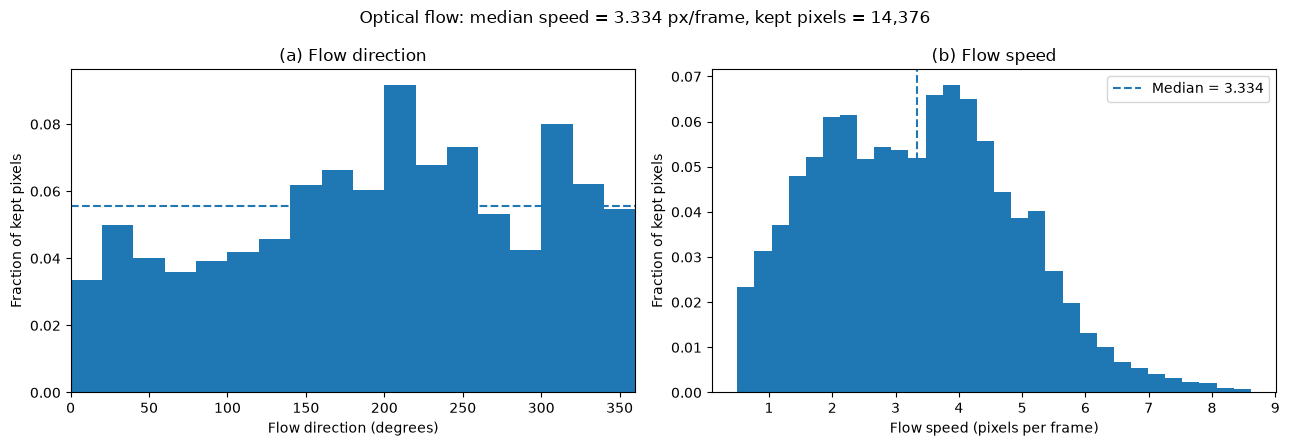

Median speed: 3.3340225
Pixels kept: 14376


In [44]:
angles = np.concatenate(all_angles)
speeds = np.concatenate(all_speeds)

median_speed = np.median(speeds)
n_kept = len(speeds)

# Plot both histograms
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Direction: 18 bins, each 20 degrees
axes[0].hist(
    angles,
    bins=np.linspace(0, 360, 19),
    weights=np.ones(len(angles)) / n_kept
)
axes[0].axhline(1 / 18, linestyle="--")
axes[0].set(
    xlabel="Flow direction (degrees)",
    ylabel="Fraction of kept pixels",
    title="(a) Flow direction",
    xlim=(0, 360)
)

# (b) Speed
axes[1].hist(
    speeds,
    bins=30,
    weights=np.ones(n_kept) / n_kept
)
axes[1].axvline(
    median_speed,
    linestyle="--",
    label=f"Median = {median_speed:.3f}"
)
axes[1].set(
    xlabel="Flow speed (pixels per frame)",
    ylabel="Fraction of kept pixels",
    title="(b) Flow speed"
)
axes[1].legend()

fig.suptitle(
    f"Optical flow: median speed = {median_speed:.3f} px/frame, "
    f"kept pixels = {n_kept:,}"
)
fig.tight_layout()
plt.show()

print("Median speed:", median_speed)
print("Pixels kept:", n_kept)


# 2. Baseline: ConvLSTM

## Architecture

In [47]:


class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels=64, kernel_size=3, stride=1, padding=1):
        super().__init__()

        self.hidden_channels = hidden_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        # One convolution computes all four gates:
        # input, forget, output, and candidate
        self.conv = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size=self.kernel_size,
            stride=self.stride,
            padding=self.padding,
            bias=True,
        )

    def forward(self, x, state):
        h_prev, c_prev = state

        # Combine input and previous hidden state
        combined = torch.cat([x, h_prev], dim=1)
        gates = self.conv(combined)

        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = (f * c_prev) + (i * g)
        h = o * torch.tanh(c)

        return h, c


In [49]:
class ConvLSTMForecaster(nn.Module):
    def __init__(self, hidden_channels=64):
        super().__init__()

        self.hidden_channels = hidden_channels

        self.lstm1 = ConvLSTMCell(
            input_channels=16,
            hidden_channels=hidden_channels,
        )

        self.lstm2 = ConvLSTMCell(
            input_channels=hidden_channels,
            hidden_channels=hidden_channels,
        )

        # Convert 64 hidden channels to 16 channels
        self.output_conv = nn.Conv2d(
            hidden_channels, 16, kernel_size=1, bias=True
        )

    def init_state(self, batch_size, height, width, device):
        shape = (batch_size, self.hidden_channels, height, width)

        h1 = torch.zeros(shape, device=device)
        c1 = torch.zeros(shape, device=device)
        h2 = torch.zeros(shape, device=device)
        c2 = torch.zeros(shape, device=device)

        return (h1, c1), (h2, c2)

    def forward(self, x):
        B, T, C, H, W = x.shape

        assert T == 5
        assert C == 1
        assert H == 64 and W == 64

        (h1, c1), (h2, c2) = self.init_state(
            B, H // 4, W // 4, x.device
        )

        prediction = None
        outputs = []

        # 9 steps total:
        # Steps 1-5 consume real input frames.
        # Steps 6-9 consume the model's previous prediction.
        for t in range(9):
            if t < 5:
                frame = x[:, t]
            else:
                frame = prediction

            frame = F.pixel_unshuffle(frame, 4)

            h1, c1 = self.lstm1(frame, (h1, c1))
            h2, c2 = self.lstm2(h1, (h2, c2))

            prediction = self.output_conv(h2)

            prediction = F.pixel_shuffle(prediction, 4)

            prediction = torch.sigmoid(prediction)

            # Steps 5-9 predict the five target frames
            if t >= 4:
                outputs.append(prediction)

        return torch.stack(outputs, dim=1)


In [81]:
model = ConvLSTMForecaster(hidden_channels=64).to(device)

print("Parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Parameters: 480784


## Training and evaluation

### Optimiser and scheduler

In [82]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
batch_size = 32
epochs = 30


### Loss

In [83]:

def mse_loss(predictions, targets, target_lengths):

    batch_size = predictions.shape[0]
    video_losses = []

    for i in range(batch_size):
        n = target_lengths[i]

        # Average squared error over valid frames and all pixels
        video_loss = (
            (predictions[i, :n] - targets[i, :n]) ** 2
        ).mean()

        video_losses.append(video_loss)

    # Every video contributes equally
    return torch.stack(video_losses).mean()


### Training

In [84]:
seed = 1

torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

In [ ]:
videos = train_data_tensor.permute(1, 0, 2, 3).unsqueeze(2).contiguous()

train_losses = []
train_times = []

num_videos = videos.shape[0]

# Five input frames and five target frames
offset = torch.arange(5)

for epoch in range(epochs):

    model.train()
    permutation = torch.randperm(num_videos)

    total_loss = 0.0
    num_batches = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.perf_counter()

    for start in range(0, num_videos, batch_size):
        indices = permutation[start:start + batch_size]
        batch_size_actual = len(indices)

        # Normal-speed start frames:
        starts = torch.randint(0, 11, (batch_size_actual,))

        # Gather 5 input frames and the next 5 target frames
        input_indices = starts[:, None] + offset[None, :]
        target_indices = starts[:, None] + 5 + offset[None, :]

        X = videos[indices[:, None], input_indices]
        Y = videos[indices[:, None], target_indices]

        X = X.to(device)
        Y = Y.to(device)

        optimizer.zero_grad()

        # Predict five future frames
        Y_pred = model(X)

        target_lengths = torch.full(
            (batch_size_actual,), 5, dtype=torch.long, device=device
        )

        # MSE over batch, horizons, channels, and pixels
        loss = mse_loss(Y_pred, Y, target_lengths=target_lengths)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    if device.type == "cuda":
        torch.cuda.synchronize()

    t1 = time.perf_counter()
    elapsed_time = t1 - t0

                    
    train_times.append(elapsed_time)

    avg_loss = total_loss / num_batches
    train_losses.append(avg_loss)
    print(f"Epoch [{epoch + 1:02d}/{epochs}], "
          f"Loss: {avg_loss:.6f}, Time: {elapsed_time:.6f} s")


Epoch [01/30], Loss: 0.046809, Time: 21.211209 s
Epoch [02/30], Loss: 0.039712, Time: 20.325279 s
Epoch [03/30], Loss: 0.038332, Time: 19.759781 s
Epoch [04/30], Loss: 0.035901, Time: 20.285234 s
Epoch [05/30], Loss: 0.033540, Time: 19.753008 s
Epoch [06/30], Loss: 0.031370, Time: 19.873314 s
Epoch [07/30], Loss: 0.030347, Time: 21.775449 s
Epoch [08/30], Loss: 0.029620, Time: 20.933039 s
Epoch [09/30], Loss: 0.029039, Time: 19.853389 s
Epoch [10/30], Loss: 0.028541, Time: 20.196211 s
Epoch [11/30], Loss: 0.028058, Time: 18.619492 s
Epoch [12/30], Loss: 0.027499, Time: 18.784465 s
Epoch [13/30], Loss: 0.026981, Time: 20.350543 s
Epoch [14/30], Loss: 0.026451, Time: 18.695783 s
Epoch [15/30], Loss: 0.025912, Time: 21.323160 s
Epoch [16/30], Loss: 0.025355, Time: 20.213291 s
Epoch [17/30], Loss: 0.024882, Time: 18.454723 s
Epoch [18/30], Loss: 0.024393, Time: 18.885994 s
Epoch [19/30], Loss: 0.023913, Time: 18.975143 s
Epoch [20/30], Loss: 0.023504, Time: 19.287359 s
Epoch [21/30], Loss:

In [86]:
torch.save(model.state_dict(), f"trained_models/modelA_seed{seed}.pth")

### Train and execution time charts

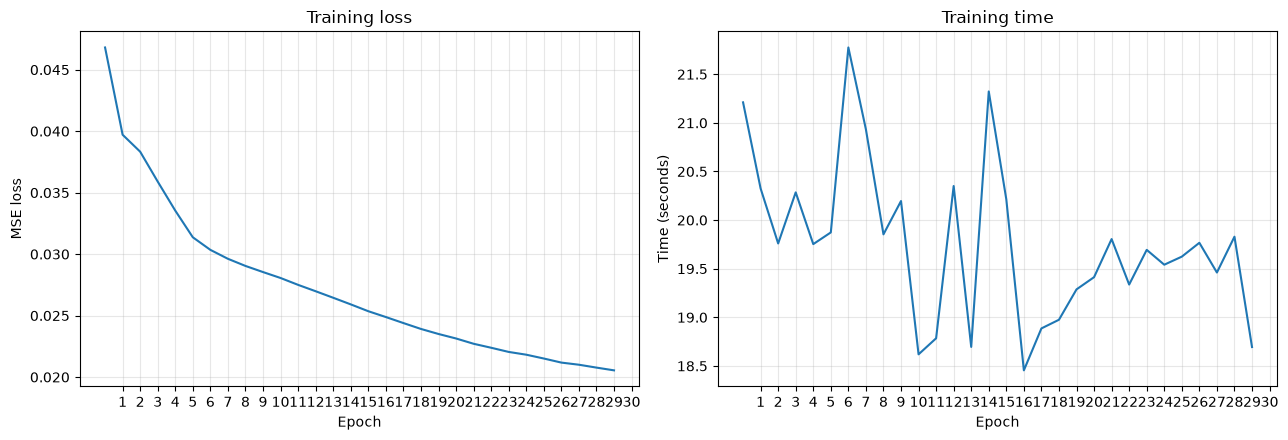

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(train_losses)
axes[1].plot(train_times)

epochs_axis = range(1, len(train_losses) + 1)

axes[0].set(
    title="Training loss",
    xlabel="Epoch",
    ylabel="MSE loss"
)
axes[0].set_xticks(epochs_axis)
axes[0].grid(True, alpha=0.3)

axes[1].set(
    title="Training time",
    xlabel="Epoch",
    ylabel="Time (seconds)"
)
axes[1].set_xticks(epochs_axis)
axes[1].grid(True, alpha=0.3)

fig.tight_layout()

# Save the figures
fig.savefig(f"figures/training_curves_modelA_seed{seed}.png", dpi=300, bbox_inches="tight")

plt.show()

## Evaluation

### Get 5 frames each for X and Y from test data

In [93]:
test_data_tensor.shape

torch.Size([20, 1000, 64, 64])

In [94]:
test_data_tensor = test_data_tensor.permute(1, 0, 2, 3).unsqueeze(2).contiguous()

X_test = test_data_tensor[:, :5].contiguous()
Y_test = test_data_tensor[:, 5:10].contiguous()

assert X_test.shape == (1000, 5, 1, 64, 64), X_test.shape
assert Y_test.shape == (1000, 5, 1, 64, 64), Y_test.shape


### Baseline Predictors

In [95]:
def blank_predictor(x):
    return torch.zeros_like(x)

def copy_last_predictor(x):
    return x[:, -1:, :, :, :].expand(-1, 5, -1, -1, -1)


### Model Evaluator

In [ ]:
def evaluate_model(predict_fn, X, Y, batch_size=32):
    all_errors = []
    total_inference_seconds = 0.0

    # Warm-up on a separate batch; exclude warm-up from timing
    warmup_x = X[:min(batch_size, len(X))].to(device)

    with torch.no_grad():
        _ = predict_fn(warmup_x)
        
    if device.type == "cuda":
        torch.cuda.synchronize()

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            end = min(start + batch_size, len(X))

            # Transfer before starting the inference timer
            xb = X[start:end].to(device)
            yb = Y[start:end].to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            t0 = time.perf_counter()

            pred = predict_fn(xb)

            if device.type == "cuda":
                torch.cuda.synchronize()
                
            total_inference_seconds += time.perf_counter() - t0

            # MSE for each video and forecast horizon
            errors = ((pred - yb) ** 2).mean(dim=(2, 3, 4))
            all_errors.append(errors.cpu())

    errors = torch.cat(all_errors, dim=0)
    mse_h = errors.mean(dim=0).numpy()
    e5 = float(mse_h.mean())

    return {
        "mse_h": mse_h,
        "e5": e5,
        "inference_seconds": total_inference_seconds,
        "ms_per_video": total_inference_seconds / len(X) * 1000,
    }



### Evaluate blank and copy-last

In [97]:
results = {}

results["Blank"] = evaluate_model(
    blank_predictor, X_test, Y_test, batch_size
)

results["Copy-last"] = evaluate_model(
    copy_last_predictor, X_test, Y_test, batch_size
)


### Evaluate Model A for both seeds

In [98]:
seed_results = {}

for seed in [0, 1]:
    model = ConvLSTMForecaster().to(device)
    checkpoint = f"trained_models/modelA_seed{seed}.pth"

    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )

    model.eval()

    params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    result = evaluate_model(model, X_test, Y_test, batch_size)
    result["params"] = params

    seed_results[seed] = result
    results[f"Model A (seed {seed})"] = result

    print(f"\nModel A, seed {seed}")

    for h, mse in enumerate(result["mse_h"], start=1):
        print(f"MSE_{h}: {mse:.6f}")

    print(f"E(5): {result['e5']:.6f}")

    print(f"Inference time for 1,000 videos: "
          f"{result['inference_seconds']:.4f} seconds")
    
    print(f"Mean time per video: {result['ms_per_video']:.4f} ms")
    print(f"Trainable parameters: {params}")




Model A, seed 0
MSE_1: 0.016310
MSE_2: 0.019717
MSE_3: 0.022035
MSE_4: 0.023786
MSE_5: 0.025501
E(5): 0.021470
Inference time for 1,000 videos: 0.3882 seconds
Mean time per video: 0.3882 ms
Trainable parameters: 480784

Model A, seed 1
MSE_1: 0.016029
MSE_2: 0.018906
MSE_3: 0.020954
MSE_4: 0.022648
MSE_5: 0.024342
E(5): 0.020576
Inference time for 1,000 videos: 0.3019 seconds
Mean time per video: 0.3019 ms
Trainable parameters: 480784


## How far can information travel?

### Final Results Table

In [100]:
mean_mse = np.mean(
    [seed_results[s]["mse_h"] for s in [0, 1]], axis=0
)
mean_e5 = np.mean(
    [seed_results[s]["e5"] for s in [0, 1]]
)

# Parameter count is identical for both seeds
model_a_params = seed_results[0]["params"]

table_rows = []

for name in ["Model A", "Blank", "Copy-last"]:
    if name == "Model A":
        mse_h = mean_mse
        e5 = mean_e5
        params = model_a_params
        inference_time = np.mean([
            seed_results[s]["inference_seconds"] for s in [0, 1]
        ])
    else:
        r = results[name]
        mse_h = r["mse_h"]
        e5 = r["e5"]
        params = 0
        inference_time = r["inference_seconds"]

    row = {
        "Model": name,
        **{f"MSE_{h+1}": float(mse_h[h]) for h in range(5)},
        "E(5)": float(e5),
        "Trainable parameters": params,
        "Inference time (s / 1000 videos)": inference_time,
    }
    table_rows.append(row)

table = pd.DataFrame(table_rows)

print("\nTable 2: Test results")
display(table.round(6))

print("\nPer-seed Model A results")
seed_table = pd.DataFrame([
    {
        "Seed": s,
        **{f"MSE_{h+1}": float(seed_results[s]["mse_h"][h])
           for h in range(5)},
        "E(5)": seed_results[s]["e5"],
        "Inference time (s)": seed_results[s]["inference_seconds"],
        "Parameters": seed_results[s]["params"],
    }
    for s in [0, 1]
])
display(seed_table.round(6))

# Save tables for your report
table.to_csv("results/table2_test_results.csv", index=False)
seed_table.to_csv("results/model_a_seed_results.csv", index=False)

print("\nSaved: results/table2_test_results.csv")
print("Saved: results/model_a_seed_results.csv")


Table 2: Test results


,Model,MSE_1,MSE_2,MSE_3,MSE_4,MSE_5,E(5),Trainable parameters,Inference time (s / 1000 videos)
0,Model A,0.016169,0.019311,0.021494,0.023217,0.024921,0.021023,480784,0.345052
1,Blank,0.042610,0.042570,0.042576,0.042532,0.042530,0.042564,0,0.002861
2,Copy-last,0.049164,0.060420,0.066889,0.070779,0.073160,0.064082,0,0.002081



Per-seed Model A results


,Seed,MSE_1,MSE_2,MSE_3,MSE_4,MSE_5,E(5),Inference time (s),Parameters
0,0,0.016310,0.019717,0.022035,0.023786,0.025501,0.021470,0.388197,480784
1,1,0.016029,0.018906,0.020954,0.022648,0.024342,0.020576,0.301907,480784



Saved: results/table2_test_results.csv
Saved: results/model_a_seed_results.csv


### Figure 2 Results

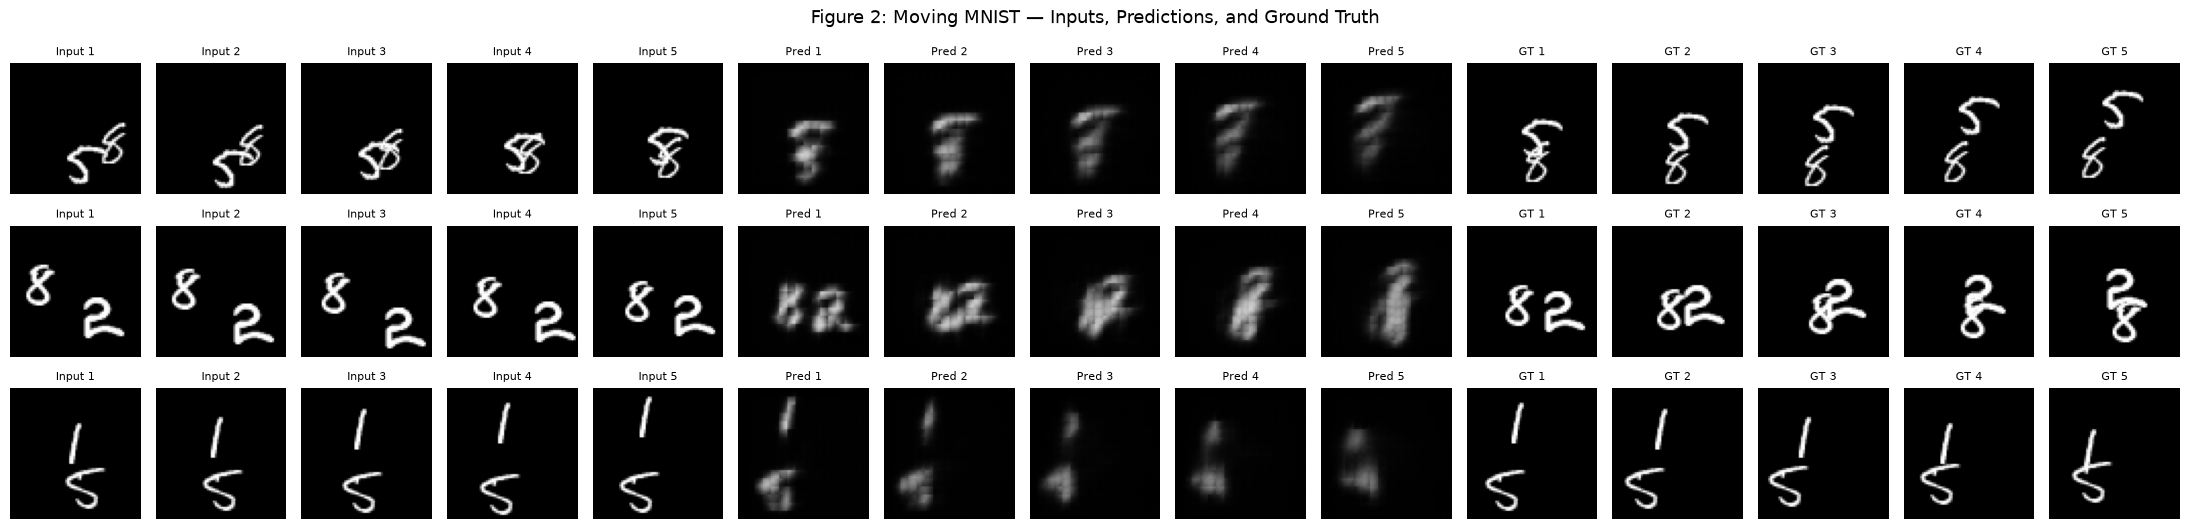

In [102]:
# Load the seed-0 model
model = ConvLSTMForecaster().to(device)
model.load_state_dict(
    torch.load(
        "trained_models/modelA_seed0.pth",
        map_location=device,
        weights_only=True
    )
)
model.eval()

# test_data_tensor has shape (20, 1000, 64, 64)
# Convert to (1000, 20, 1, 64, 64)
if test_data_tensor.ndim == 4:
    test_videos = (
        test_data_tensor.permute(1, 0, 2, 3)
        .unsqueeze(2)
        .contiguous()
    )
else:
    test_videos = test_data_tensor


video_indices = [0, 1, 2]

inputs = test_videos[video_indices, :5].float()
targets = test_videos[video_indices, 5:10].float()

with torch.no_grad():
    predictions = model(inputs.to(device)).cpu()

inputs = inputs.cpu()

# Plot 3 videos x 15 frames
fig, axes = plt.subplots(3, 15, figsize=(22, 5.5))

for row in range(3):
    for col in range(15):
        ax = axes[row, col]

        if col < 5:
            frame = inputs[row, col, 0]
            title = f"Input {col+1}"
        elif col < 10:
            frame = predictions[row, col-5, 0]
            title = f"Pred {col-4}"
        else:
            frame = targets[row, col-10, 0]
            title = f"GT {col-9}"

        ax.imshow(frame.numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=8)
        ax.axis("off")

    axes[row, 0].set_ylabel(
        f"Test video {video_indices[row]}",
        fontsize=10
    )

fig.suptitle(
    "Figure 2: Moving MNIST — Inputs, Predictions, and Ground Truth",
    fontsize=13
)

fig.tight_layout()
fig.savefig("figures/figure2_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

### Questions


#### Q2.3 — Estimate Model A's Reach

The original image is of size $64 \times 64$, but `PixelUnshuffle(4)` converts it into a $16 \times 16$ grid. Each grid cell represents 4 original pixels:

$$
\frac{64}{16} = 4 \text{ pixels}
$$

Only $3 \times 3$ convolutions move information. Since the architecture has two ConvLSTM layers, each using a $3 \times 3$ convolution, information can travel across two grid cells.

Therefore, the overall reach is:

$$
\text{Reach} = 2 \times 4 = 8 \text{ pixels}
$$

#### Q2.4 — Comparison with Baselines

Model A has a much lower MSE and $E^{(5)}$ compared to the other two baselines, with a reduction of 50.6% compared to Blank and 67.2% compared to Copy-last. The error increases at each forecast step, although the increase becomes smaller at later steps compared to the initial steps. When digits overlap, the predictions become blurry and the individual digit shapes are harder to distinguish. A lower MSE cannot be assumed just because the digits overlap, as it depends on how closely the predicted pixels match the ground truth.

#### Q2.5 — Predictions Before Experiments

I predict that Model A will pass the mirror and rotation tests. It will likely break down at speed $k = 3$, as the digits may move beyond its reach of 8 pixels per time step, making them harder to track.


# 3. Testing the Baseline